# Valuing the option to store maize in Uasin-Gishu

**Erdős Institute — Quantitative Methods in Finance, Fall 2026 — course project**

**Question.** A Uasin-Gishu farmer holding maize after the October–December harvest can sell
now or store it (in agriBORA's certified Eldoret warehouse, or on the farm) and sell in any
later month. What is the option to delay the sale worth, what month-by-month rule captures
it, and does that rule beat selling at harvest on real Eldoret prices after realistic costs?

Maize in Kenya cannot be hedged (no exchange-traded maize futures), so the decision uses the
**real-world seasonal drift** of prices rather than risk-neutral pricing. The plan, inputs and
sources are in [`docs/agribora_worksheet.md`](docs/agribora_worksheet.md).

| Part | Steps | Status |
|---|---|---|
| Data, seasonal cycle, seasonal drift, volatility and GBM checks | 1–4 | done |
| Forecast check; option value under GBM | 5–6 | done |
| Monte Carlo check, backtest, sensitivities, conclusions | 7–9 | done |

All prices are **nominal** KSh per kg (wholesale, Eldoret). The loan rate used for discounting
later (≈ 15%/yr) is also nominal, so a nominal drift is the consistent choice; inflation then
sits inside the drift rather than needing a CPI series.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import numpy as np
import pandas as pd
from scipy import stats
from scipy.optimize import least_squares

import quantkit as qk

sys.path.insert(0, "figures")
import seasonality as season      # tests used for figures/seasonality_uasin_gishu_vs_nairobi.png
%matplotlib inline

rng = np.random.default_rng(2026)

# chart styling (same palette as figures/)
SURF, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
BLUE, ORANGE, AQUA, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#6250d6"
plt.rcParams.update({"figure.facecolor": SURF, "axes.facecolor": SURF, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRID, "axes.edgecolor": INK2,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.labelcolor": INK2,
                     "figure.dpi": 110})
MONTHS = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]

## Step 1 — Load and inspect the price series (Lecture 3a)

`data/processed/wfp_monthly_wholesale.csv` is built by `data/make_data.py` from WFP market
monitoring (Eldoret town, 2006–2025) with five gaps filled from KAMIS Eldoret Main Market,
which matches WFP where both exist. See `data/README.md` for every splice.

In [2]:
raw = pd.read_csv("data/processed/wfp_monthly_wholesale.csv")
ug = raw[raw.county == "Uasin-Gishu"].copy()
ug["month"] = pd.PeriodIndex(ug.month, freq="M")
ug = ug.set_index("month")
price = ug.wholesale_kes_per_kg                     # nominal KSh/kg, NaN = no observation

print(f"{price.index.min()} -> {price.index.max()}: {price.notna().sum()} of {len(price)} months observed")
print("missing:", [str(m) for m in price[price.isna()].index])
print("\nsource of each month:")
print(ug.source.value_counts().to_string())
price.describe().round(1)

2006-01 -> 2025-06: 225 of 234 months observed
missing: ['2020-04', '2020-05', '2023-12', '2024-01', '2024-10', '2024-11', '2024-12', '2025-01', '2025-03']

source of each month:
source
WFP Eldoret, Maize per kg                            173
WFP Eldoret, Maize (white, dry) per 90 kg / 90        42
missing                                                9
WFP Eldoret, Maize (white) per 90 kg / 90              5
KAMIS Eldoret Main Market (Zindi), monthly median      5


count    225.0
mean      31.1
std       15.1
min       10.4
25%       22.0
50%       29.2
75%       35.9
max       90.4
Name: wholesale_kes_per_kg, dtype: float64

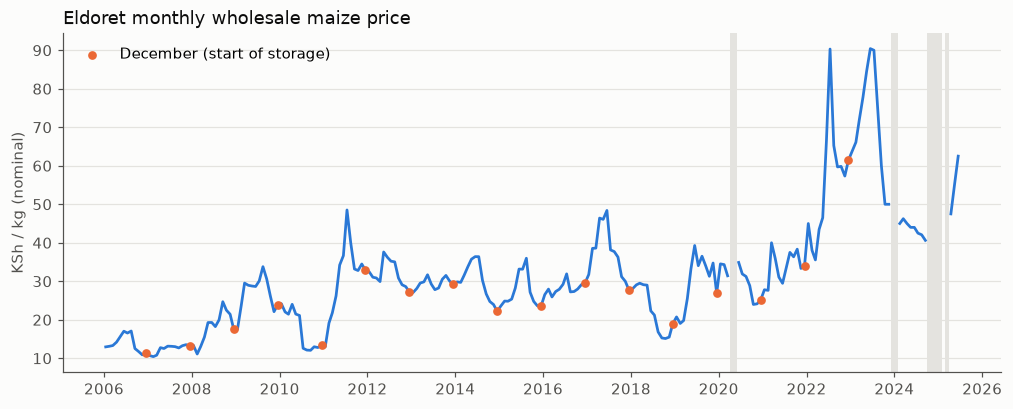

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
t = price.index.to_timestamp() + pd.Timedelta(days=14)
for m in price[price.isna()].index:                  # grey = no price that month
    d = m.to_timestamp() + pd.Timedelta(days=14)
    ax.axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15), color=GRID, lw=0, zorder=0)
ax.plot(t, price.values, color=BLUE, lw=1.8)
# harvest-window lows: mark each December
dec = price[(price.index.month == 12)].dropna()
ax.scatter(dec.index.to_timestamp() + pd.Timedelta(days=14), dec.values, s=22, color=ORANGE,
           zorder=3, label="December (start of storage)")
ax.set_ylabel("KSh / kg (nominal)")
ax.set_title("Eldoret monthly wholesale maize price", loc="left", color=INK)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.legend(frameon=False, loc="upper left"); ax.grid(axis="x", visible=False)
plt.show()

**What to note.** Prices trend up (≈ 13 → 35 KSh/kg over 2006–2021, roughly Kenyan inflation),
swing seasonally every year, and spike in 2022–23 (peaks ≈ 90 KSh/kg in July 2022 and June 2023,
confirmed by KAMIS). Everything below is estimated on the **full series, 2006-01 → 2025-06**.
The 2022–23 seasons are 2 of 17; how much of storage's value comes from them is answered
season by season in the Step 8 backtest.

Monthly log returns $r_t = \log(P_t / P_{t-1})$ are used throughout. A return is only defined
when **both** consecutive months are observed; returns across a missing month are dropped
rather than counted as a one-month move.

In [4]:
r = np.log(price).diff().dropna()                    # NaN wherever either month is missing
r.name = "log_return"
full = pd.period_range(r.index.min(), r.index.max(), freq="M")
print(f"{len(r)} monthly returns, {r.index.min()} -> {r.index.max()}")

220 monthly returns, 2006-02 -> 2025-06


## Step 2 — The seasonal cycle (Lecture 8)

If prices do not rise predictably after harvest, there is no reason to store. Each season is
followed from December to November and measured against its own December–January (harvest)
price level. Then four tests from `figures/seasonality.py`:

* **Kruskal–Wallis / ANOVA:** do the 12 calendar months have different mean returns?
* **Annual cycle + random-phase permutation test:** fit one sine wave to the returns; compare
  its size with 5,000 reshuffles in which each year is rotated by its own random number of
  months (this destroys any timing shared across years but keeps each year's returns);
* **Sign test:** was the May–July price above the December–January level more often than chance?

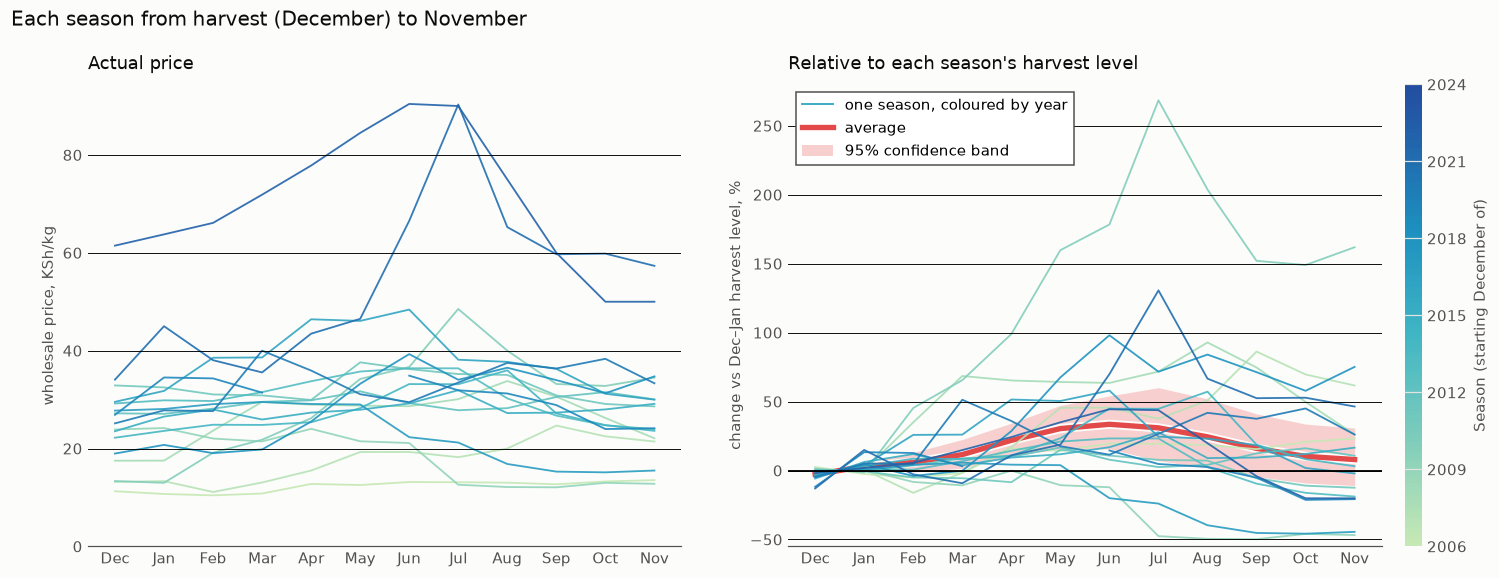

Kruskal-Wallis p                 0.000023
ANOVA p                          0.000081
annual cycle, %/month            6.674546
permutation p                      0.0002
seasons up Dec-Jan -> May-Jul       15/17
sign test p                      0.001175
dtype: object

In [5]:
res = season.run_tests(price, np.random.default_rng(2026))
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

fig, (axL, axR) = plt.subplots(1, 2, figsize=(14, 5.6))

# right: % relative to each season's Dec-Jan harvest level (lines coloured by year, average, band)
top, bottom = season.panel(axR, "Uasin-Gishu", price, res)
axR.set_ylim(25 * np.floor(bottom / 25) - 5, 25 * np.ceil(top / 25) + 5)
axR.set_ylabel("change vs Dec–Jan harvest level, %")
axR.set_title("Relative to each season's harvest level", loc="left", color=INK, pad=10)
axR.grid(axis="x", visible=False)
axR.legend(handles=[Line2D([], [], color=season.SEASON_CMAP(0.55), lw=1.2, label="one season, coloured by year"),
                    Line2D([], [], color=season.AVG, lw=3.5, label="average"),
                    Patch(facecolor=season.AVG_BAND, label="95% confidence band")],
           loc="upper left", **season.LEGEND_BOX)

# left: actual price for the same seasons, Dec -> Nov
seasons_used = season.season_paths(price).index            # same seasons as the right panel
for yr in seasons_used:
    months = [pd.Period(f"{yr-1}-12", "M")] + [pd.Period(f"{yr}-{m:02d}", "M") for m in range(1, 12)]
    axL.plot(range(12), price.reindex(months).values, color=season.SEASON_CMAP(season.SEASON_NORM(yr - 1)),
             lw=1.2, alpha=.9, zorder=2.2)
axL.set_xticks(range(12), ["Dec"] + MONTHS[:11])
axL.set_ylabel("wholesale price, KSh/kg")
axL.set_ylim(0, None)
axL.set_title("Actual price", loc="left", color=INK, pad=10)
axL.set_axisbelow(False)
axL.grid(axis="y", color="black", lw=.6); axL.grid(axis="x", visible=False)
for sp in ("top", "right", "left"):
    axL.spines[sp].set_visible(False)
axL.tick_params(length=0)

fig.suptitle("Each season from harvest (December) to November", x=0.01, ha="left", color=INK, fontsize=13)
fig.subplots_adjust(left=0.06, right=0.9, top=0.86, wspace=0.18)
pos = axR.get_position()
season.season_colorbar(fig, fig.add_axes([0.915, pos.y0, 0.011, pos.height]))
plt.show()

pd.Series({"Kruskal-Wallis p": res["kw_p"], "ANOVA p": res["anova_p"],
           "annual cycle, %/month": 100 * res["amp"], "permutation p": res["amp_p"],
           "seasons up Dec-Jan -> May-Jul": f"{res['pos']}/{len(res['rises'])}",
           "sign test p": res["sign_p"]})

**Average price change by calendar month.** Mean log return into each month with standard
errors from `qk.mc_estimate` (each month's returns treated as a sample). These are plotted
together with the fitted seasonal drift in Step 3.

In [6]:
rows = []
for m in range(1, 13):
    x = r[r.index.month == m].values
    mean, se = qk.mc_estimate(x)
    rows.append({"month": MONTHS[m - 1], "n": len(x), "mean": mean, "se": se})
mm = pd.DataFrame(rows).set_index("month")
mm.loc[["Dec"] + MONTHS[:11]].round(4)        # displayed in season order, Dec -> Nov

,n,mean,se
month,,,
Dec,17,-0.0157,0.0256
Jan,17,0.0572,0.0220
Feb,18,0.0273,0.0340
Mar,19,0.0494,0.0253
Apr,18,0.0762,0.0236
May,19,0.0684,0.0269
Jun,19,0.0393,0.0282
Jul,19,-0.0207,0.0402
Aug,19,-0.0446,0.0297


**Reading.** Prices fall from August to December (harvest arriving) and rise from January to
June (stocks running down). The cycle is significant in every test, and the price was higher in
May–July than at the December–January harvest level in 15 of 17 seasons. Storage has a reason
to exist; the question for Steps 6–8 is whether the rise beats interest, fees and losses after
accounting for the bad years (the two seasons where it fell).

## Step 3 — Seasonal drift (Lecture 4; least-squares calibration as in F26 L12)

Twelve separate monthly means are noisy (each rests on ≈ 17–19 returns). We smooth them with
a few annual harmonics,

$$ g(m) = a + \sum_{k=1}^{K} \Big[ b_k \sin\tfrac{2\pi k m}{12} + c_k \cos\tfrac{2\pi k m}{12} \Big], $$

where $g(m)$ is the expected log return **into** calendar month $m$. The coefficients are
fitted with `scipy.optimize.least_squares`, the same tool Lecture 12 uses to calibrate Heston.
$K$ is chosen by **leave-one-year-out cross-validation**: hold out each year, fit on the rest,
and score the squared error on the held-out year.

In [7]:
def design(months, K):
    cols = [np.ones(len(months))]
    for k in range(1, K + 1):
        cols += [np.sin(2 * np.pi * k * months / 12), np.cos(2 * np.pi * k * months / 12)]
    return np.column_stack(cols)

def fit_drift(r, K):
    X, y = design(r.index.month.values, K), r.values
    res = least_squares(lambda beta: X @ beta - y, x0=np.zeros(X.shape[1]))
    return res.x

def g_of(beta, K, months=np.arange(1, 13)):
    return design(months, K) @ beta

def cv_score(r, K):
    err = []
    for yr in sorted(set(r.index.year)):
        tr, te = r[r.index.year != yr], r[r.index.year == yr]
        if K == "12 means":
            pred = tr.groupby(tr.index.month).mean().reindex(te.index.month).values
        else:
            pred = g_of(fit_drift(tr, K), K, te.index.month.values)
        err.append((te.values - pred) ** 2)
    return np.concatenate(err).mean()

cv = pd.Series({(f"K={K}" if K != "12 means" else K): cv_score(r, K) for K in [0, 1, 2, 3, "12 means"]})
(cv / cv["K=0"]).round(4).rename("CV MSE relative to constant drift")

K=0         1.0000
K=1         0.8754
K=2         0.8911
K=3         0.8998
12 means    0.9287
Name: CV MSE relative to constant drift, dtype: float64

chosen K = 1


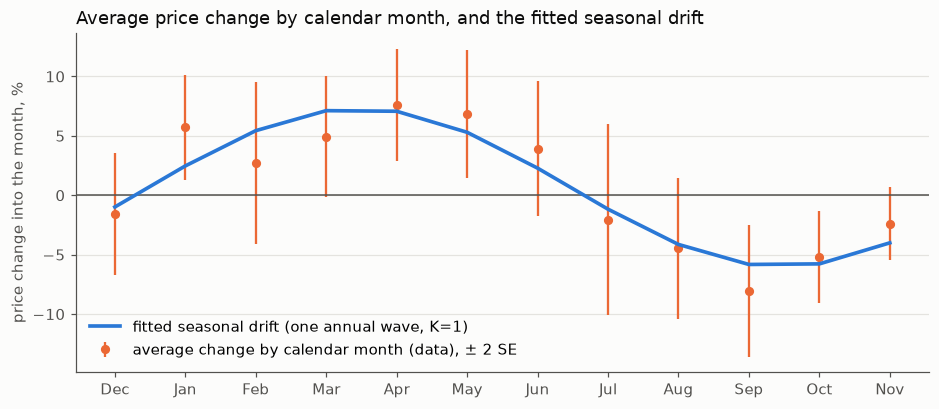

Dec     0.0
Jan     2.5
Feb     8.2
Mar    16.2
Apr    24.7
May    31.5
Jun    34.5
Jul    33.0
Aug    27.6
Name: expected price vs December, %, dtype: float64

In [8]:
K = int(cv.drop("12 means").idxmin().split("=")[1])
print("chosen K =", K)
g = pd.Series(g_of(fit_drift(r, K), K), index=MONTHS)

SEASON_ORDER = ["Dec"] + MONTHS[:11]          # plot in season order: harvest (Dec) -> Nov
fig, ax = plt.subplots(figsize=(10, 4))
ax.errorbar(np.arange(12), 100 * mm.loc[SEASON_ORDER, "mean"], yerr=200 * mm.loc[SEASON_ORDER, "se"],
            fmt="o", ms=5, color=ORANGE, capsize=0, lw=1.5,
            label="average change by calendar month (data), ± 2 SE", zorder=2)
ax.plot(range(12), 100 * g[SEASON_ORDER].values, color=BLUE, lw=2.4,
        label=f"fitted seasonal drift (one annual wave, K={K})", zorder=3)
ax.axhline(0, color=INK2, lw=1)
ax.set_xticks(range(12), SEASON_ORDER); ax.set_ylabel("price change into the month, %")
ax.set_title("Average price change by calendar month, and the fitted seasonal drift", loc="left", color=INK)
ax.legend(frameon=False, loc="lower left"); ax.grid(axis="x", visible=False)
plt.show()

# implied average seasonal path from December (the storage start), as % above December
path = 100 * (np.exp(np.cumsum(np.r_[0, g[MONTHS[:8]].values])) - 1)
pd.Series(path, index=["Dec"] + MONTHS[:8]).round(1).rename("expected price vs December, %")

## Step 4 — Volatility and the GBM assumptions (Lectures 3a, 8, 11b)

### 4a. Raw returns

GBM assumes i.i.d. normal log returns. First on the raw returns: normality, autocorrelation of
returns (momentum / mean reversion) and of absolute returns (volatility clustering).

In [9]:
nt = qk.test_normality(r)
lb = qk.ljung_box(r.values, lags=12)
lba = qk.ljung_box(np.abs(r.values), lags=12)
pd.Series({"n returns": len(r), "mean (annualized)": 12 * r.mean(),
           "volatility (annualized)": qk.annualized_vol(r, periods_per_year=12),
           "skew": nt["skewness"], "excess kurtosis": nt["excess_kurtosis"],
           "normality p (D'Agostino)": nt["p_dagostino"], "normality p (Shapiro)": nt["p_shapiro"],
           "Ljung-Box r, 12 lags p": lb["lb_pvalue"][-1],
           "Ljung-Box |r|, 12 lags p": lba["lb_pvalue"][-1]}).round(4)

n returns                   220.0000
mean (annualized)             0.0773
volatility (annualized)       0.4338
skew                         -0.0208
excess kurtosis               1.7887
normality p (D'Agostino)      0.0020
normality p (Shapiro)         0.0000
Ljung-Box r, 12 lags p        0.0039
Ljung-Box |r|, 12 lags p      0.4642
dtype: float64

Ljung–Box on raw returns at 12 lags partly picks up the **seasonal cycle itself** (returns in
the same calendar month are alike). The honest test of the i.i.d. assumption is on returns
*after* removing the seasonal drift $g(m)$ from Step 3.

### 4b. De-seasonalized returns and σ

The residuals $\varepsilon_t = r_t - g(m_t)$ are what GBM treats as i.i.d. normal shocks. Their
standard deviation is the model's $\sigma$.

In [10]:
eps = r - g.values[r.index.month - 1]
sigma = qk.annualized_vol(eps, periods_per_year=12)
nt, lb, lba = qk.test_normality(eps), qk.ljung_box(eps.values, 12), qk.ljung_box(np.abs(eps.values), 12)
display(pd.Series({"sigma (annualized)": sigma, "raw vol (annualized)": qk.annualized_vol(r, 12),
                   "excess kurtosis": nt["excess_kurtosis"], "normality p (Shapiro)": nt["p_shapiro"],
                   "Ljung-Box eps, 12 lags p": lb["lb_pvalue"][-1],
                   "Ljung-Box |eps|, 12 lags p": lba["lb_pvalue"][-1]}).round(4))

# autocorrelation by lag on the calendar-aligned series (gaps stay NaN, so pairs are only
# formed between months that are exactly L apart)
eps_cal = eps.reindex(full)
acf = pd.Series({L: eps_cal.corr(eps_cal.shift(L)) for L in range(1, 13)})
print(f"autocorrelation of eps by lag (approx. 95% noise band ±{2 / np.sqrt(len(eps)):.2f}):")
acf.round(2).to_frame("acf").T

sigma (annualized)            0.4014
raw vol (annualized)          0.4338
excess kurtosis               1.8288
normality p (Shapiro)         0.0002
Ljung-Box eps, 12 lags p      0.0015
Ljung-Box |eps|, 12 lags p    0.0104
dtype: float64

autocorrelation of eps by lag (approx. 95% noise band ±0.13):


,1,2,3,4,5,6,7,8,9,10,11,12
acf,0.05,-0.03,-0.08,-0.04,0.18,0.14,-0.12,-0.08,-0.03,0.02,-0.05,-0.21


**Reading.** Removing the seasonal drift takes σ from ≈ 0.43 down to ≈ 0.40: part of the "raw"
volatility was the predictable cycle. What is left is **not** i.i.d. normal:

* **fat tails** (excess kurtosis ≈ 2; normality rejected): large monthly moves are more common
  than GBM allows;
* **no month-to-month momentum** (lag-1 autocorrelation ≈ 0.05), but **negative autocorrelation
  at lag 12** (≈ −0.2, outside the noise band) — this is what makes Ljung–Box reject. A month
  that was unusually strong one year tends to be weak in the same month the next year:
  year-to-year mean reversion, e.g. a shortage year followed by a recovery harvest. (Smaller
  positive values at lags 5–6, ≈ +0.15, are borderline.) Two consequences: the seasonal drift
  varies from year to year around the average estimated here, and Step 5's baseline "last
  year's same-month change" should forecast *badly*;
* **volatility clustering** (Ljung–Box on |ε| rejects): calm and turbulent stretches.

These are the main ways the GBM-based option value can be wrong. They are tested directly in
Step 8 (the backtest uses real paths, not GBM) and in the Step 10 model-risk extension
(regime-switching or Heston volatility).

### 4c. Volatility over time

Volatility over the **past 12 calendar months**, annualized: the standard deviation of the
monthly returns observed in that year × √12, computed only when at least 9 of the 12 returns
exist. Months with no price are shaded grey; windows that contain a gap (9–11 returns) are
drawn dotted, so every point means "the past year" but the less certain ones are visible.
Both the raw and the de-seasonalized returns are shown; dashed lines are full-sample values.

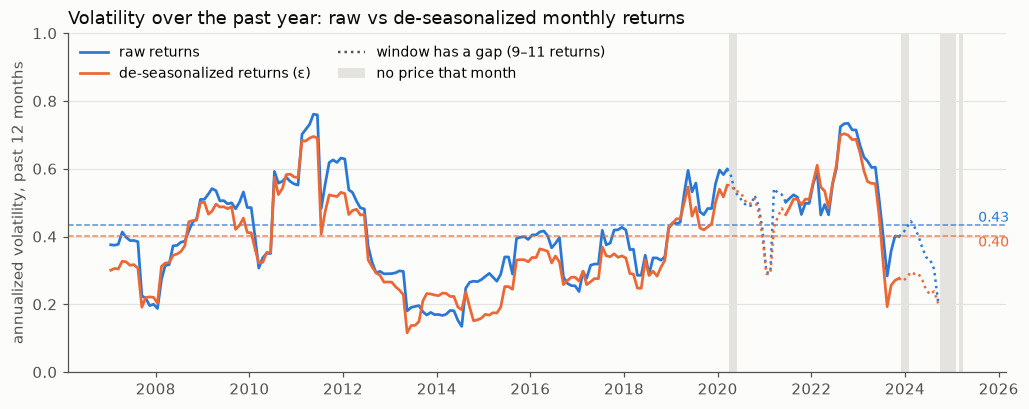

windows with a gap (9–11 returns): 24, in years [2020, 2021, 2023, 2024]
windows not computed (< 9 returns): 9: 2024-10 -> 2025-06
median: raw 0.405, de-seasonalized 0.343; max 0.76 (2011-05), min 0.13 (2014-07)
years with the highest de-seasonalized volatility: {2022: 0.7, 2011: 0.7, 2023: 0.65, 2010: 0.58, 2020: 0.55}


,n,vol
month,,
"Mar–Apr, Sep–Oct",74,0.358
harvest Nov–Feb,70,0.366
lean May–Aug,76,0.470


In [11]:
MIN_RET = 9
def vol_past_year(x):
    xc = x.reindex(full)
    vol = xc.rolling(12, min_periods=MIN_RET).std() * np.sqrt(12)
    n = xc.rolling(12, min_periods=1).count()
    vol.iloc[:11] = np.nan                  # first 11 months: less than a year of history, not a gap
    n.iloc[:11] = np.nan
    return vol, n

rv, n_ret = vol_past_year(r)
rv_eps, _ = vol_past_year(eps)
t = full.to_timestamp() + pd.Timedelta(days=14)

fig, ax = plt.subplots(figsize=(11, 4))
for m in price[price.isna()].index:                                  # grey = no price that month
    d = m.to_timestamp() + pd.Timedelta(days=14)
    ax.axvspan(d - pd.Timedelta(days=15), d + pd.Timedelta(days=15), color=GRID, lw=0, zorder=0)
complete = (n_ret == 12).values
handles = []
for series, level, col, lab, va in [(rv, qk.annualized_vol(r, 12), BLUE, "raw returns", "bottom"),
                                    (rv_eps, sigma, ORANGE, "de-seasonalized returns (ε)", "top")]:
    v = series.values
    solid = np.where(complete, v, np.nan)
    # dotted where the window has a gap; extend one point so solid and dotted segments join
    gap = complete == False
    gap_ext = gap | np.r_[gap[1:], False] | np.r_[False, gap[:-1]]
    dotted = np.where(gap_ext, v, np.nan)
    handles.append(ax.plot(t, solid, color=col, lw=1.8, label=lab)[0])
    ax.plot(t, dotted, color=col, lw=1.6, ls=":")
    ax.axhline(level, color=col, lw=1, ls="--", alpha=.8)
    ax.text(t[-1] + pd.Timedelta(days=40), level, f"{level:.2f}", color=col, va=va, fontsize=9)
handles += [Line2D([], [], color=INK2, lw=1.6, ls=":", label=f"window has a gap ({MIN_RET}–11 returns)"),
            Patch(facecolor=GRID, label="no price that month")]
ax.set_ylabel("annualized volatility, past 12 months")
ax.set_title("Volatility over the past year: raw vs de-seasonalized monthly returns", loc="left", color=INK)
ax.set_ylim(0, 1.0)                                                   # headroom for the legend
ax.legend(handles=handles, frameon=False, loc="upper left", ncol=2, fontsize=9)
ax.grid(axis="x", visible=False)
ax.xaxis.set_major_locator(mdates.YearLocator(2)); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
plt.show()

gap_years = sorted({p.year for p in full[(n_ret.values < 12) & (n_ret.values >= MIN_RET)]})
too_few = full[(n_ret.values < MIN_RET) & (np.arange(len(full)) >= 11)]
print(f"windows with a gap ({MIN_RET}–11 returns): {int(((n_ret < 12) & (n_ret >= MIN_RET)).sum())}, in years {gap_years}")
print(f"windows not computed (< {MIN_RET} returns): {len(too_few)}: {too_few.min()} -> {too_few.max()}" if len(too_few) else "none")
print(f"median: raw {rv.median():.3f}, de-seasonalized {rv_eps.median():.3f}; "
      f"max {rv.max():.2f} ({rv.idxmax()}), min {rv.min():.2f} ({rv.idxmin()})")
top_years = rv_eps.groupby(rv_eps.index.year).max().sort_values(ascending=False)
print("years with the highest de-seasonalized volatility:", {int(y): round(v, 2) for y, v in top_years.head(5).items()})

# volatility by season (de-seasonalized): harvest/early storage (Nov-Feb), lean (May-Aug), other
season_of = lambda m: "harvest Nov–Feb" if m in (11, 12, 1, 2) else ("lean May–Aug" if m in (5, 6, 7, 8) else "Mar–Apr, Sep–Oct")
eps.groupby(eps.index.month.map(season_of)).agg(n="count", vol=lambda x: x.std() * np.sqrt(12)).round(3)

**Reading.** Volatility is large (≈ 0.40/yr after removing the cycle; a broad stock index is
typically 0.15–0.20) and far from constant: calm and crisis periods alternate (peak years printed
above). The two lines pick out the same periods; the de-seasonalized one usually sits lower
because part of the raw estimate is the predictable seasonal swing. By season, the shocks are
largest in the lean months (May–Aug, ≈ 0.47) — exactly when a storer still holding grain is
exposed — and similar in the rest of the year (≈ 0.36–0.37). The 2024–25 gaps leave too few returns for a one-year estimate at
the end of the series; the line stops rather than reaching back into 2023.

### 4d. From log drift to the drift the tree and `gbm_paths` need

$g(m)$ is an expected **log** return. `qk.gbm_paths` and `qk.binomial_optimal_stopping` take an
**arithmetic** growth rate $\mu$ with $E[S_{t+dt}/S_t] = e^{\mu\,dt}$. Under GBM the two differ
by the Itô term:

$$ \mu(m) = 12\,g(m) + \tfrac{1}{2}\sigma^2 . $$

Leaving out $\tfrac12\sigma^2$ (≈ 8%/yr here, since σ ≈ 0.4) would understate the expected
price path by that much and bias the storage value down.

### 4e. Does the model reproduce history? (simulation check)

For every historical month $t$ with prices at $t$ and $t+h$ ($h$ = 3 and 6 months), simulate
the model from the same calendar month with `qk.gbm_paths` and ask whether the realized log
change falls inside the simulated 5–95% band. A well-calibrated model covers ≈ 90%.

In [12]:
mu = 12 * g + 0.5 * sigma ** 2            # arithmetic drift into each calendar month, annualized

def simulate_log_change(start_month, h, n_sims=20_000, k=4):
    # start_month: 0-based index = calendar month mod 12, so step i ends in MONTHS[(start_month + i) % 12]
    mu_path = np.repeat(mu.values[[(start_month + i) % 12 for i in range(h)]], k)
    S = qk.gbm_paths(1.0, sigma, h / 12, 0.0, h * k, n_sims, mu=mu_path, rng=rng)
    return np.log(S[:, -1])

lp = np.log(price)
coverage = []
for h in (3, 6):
    bands = {m0: np.quantile(simulate_log_change(m0, h), [.05, .95]) for m0 in range(12)}
    realized = (lp.shift(-h) - lp).dropna()
    inside = [bands[p.month % 12][0] <= x <= bands[p.month % 12][1] for p, x in realized.items()]
    coverage.append({"horizon (months)": h, "n windows": len(inside),
                     "share inside 5–95% band": np.mean(inside)})
pd.DataFrame(coverage).set_index("horizon (months)").round(3)

,n windows,share inside 5–95% band
horizon (months),,
3,215,0.893
6,212,0.896


Note on the indexing: a step that ends in calendar month $m$ uses $\mu(m)$, matching how
$g(m)$ was fitted (the return *into* month $m$). Starting at month $m_0$ (0-based index =
calendar month mod 12), the first step ends in month $m_0+1$.

### 4f. Optional: two volatility regimes (Lecture 11b)

Using the de-seasonalized past-year volatility from 4c, classify each month as high-volatility
when it is above its median, estimate the mean duration of each regime, and convert to
switching rates $\alpha$ (calm → crisis) and $\beta$ (crisis → calm) per year for
`qk.markov_vol_states`. Months where the past-year volatility could not be computed are not
classified.

In [13]:
v = rv_eps.dropna()
high = (v > v.median()).astype(int)
runs = (high != high.shift()).cumsum()
durations = high.groupby(runs).agg(["first", "size"])
mean_dur = durations.groupby("first")["size"].mean() / 12          # years
alpha, beta_rate = 1 / mean_dur[0], 1 / mean_dur[1]
regime = high.reindex(eps.index)
sig_lo = eps[regime == 0].std() * np.sqrt(12)
sig_hi = eps[regime == 1].std() * np.sqrt(12)
print(f"classified months: {int(regime.notna().sum())} of {len(eps)} returns")
print(f"mean duration: calm {mean_dur[0]:.2f} yr, crisis {mean_dur[1]:.2f} yr  ->  alpha={alpha:.2f}/yr, beta={beta_rate:.2f}/yr")
print(f"sigma calm = {sig_lo:.3f}, sigma crisis = {sig_hi:.3f} (single-regime sigma = {sigma:.3f})")

classified months: 207 of 220 returns
mean duration: calm 1.11 yr, crisis 1.26 yr  ->  alpha=0.90/yr, beta=0.79/yr
sigma calm = 0.273, sigma crisis = 0.506 (single-regime sigma = 0.401)


These regime parameters are saved for the model-risk extension (Step 10). Because "high"
is defined from a one-year window, regimes are persistent by construction; treat the
durations as rough.

### 4g. Save the model for Steps 5–9

In [14]:
params = {"window": [str(price.index.min()), str(price.index.max())], "K": K, "sigma": sigma,
          "g_log_monthly": g.to_dict(), "mu_arith_annual": mu.to_dict(),
          "regimes": {"alpha": alpha, "beta": beta_rate, "sigma_calm": sig_lo, "sigma_crisis": sig_hi}}
Path("data/processed/model_params.json").write_text(json.dumps(params, indent=2))
mu.round(3).rename("mu(m), annualized")

Jan    0.376
Feb    0.733
Mar    0.935
Apr    0.929
May    0.716
Jun    0.354
Jul   -0.060
Aug   -0.416
Sep   -0.618
Oct   -0.612
Nov   -0.400
Dec   -0.038
Name: mu(m), annualized, dtype: float64

## Summary of Steps 1–4

* **Data:** 225 of 234 months of Eldoret wholesale prices, 2006-01 → 2025-06, nominal KSh/kg.
* **Seasonality:** strong and stable — falling August → December, rising January → June,
  significant in every test; up from harvest to May–July in 15 of 17 seasons.
* **Model:** seasonal log drift $g(m)$ (harmonics, $K$ by cross-validation) + constant σ ≈ 0.40,
  with arithmetic drift $\mu(m) = 12g(m) + \sigma^2/2$ for the tree. Saved to
  `data/processed/model_params.json`.
* **Volatility:** ≈ 0.40/yr after removing the cycle, clearly time-varying (calm vs crisis
  years), largest in the lean season.
* **GBM assumptions:** shocks have fat tails, no month-to-month momentum but year-to-year mean
  reversion (lag-12 autocorrelation ≈ −0.2), and volatility clustering. GBM is an
  approximation; Steps 8 and 10 measure what that costs.
* **Coverage check:** realized 3- and 6-month price changes fall inside the model's 5–95% band
  ≈ 89–90% of the time (target 90%).

Steps 5–6 follow.

## Step 5 — Does the seasonal drift forecast? (out-of-sample validation)

The storage decision relies on the seasonal drift $g(m)$. Before using it, check that it
actually predicts prices **out of sample**. Rolling origin: for every month $t$ from 2011-01 on
(≥ 5 years of history), re-fit $g$ using only returns up to $t$, then forecast $h$ = 1 and 3
months ahead as $\hat P_{t+h} = P_t \exp\big(\sum_{i=1}^{h} g(m_{t+i})\big)$ (the median forecast,
which minimizes absolute error). Compared with three baselines:

* **last price** (random walk): $\hat P_{t+h} = P_t$;
* **12 monthly means** (unsmoothed seasonal means, also re-estimated at each $t$);
* **last year's change**: $\hat P_{t+h} = P_t \cdot P_{t+h-12} / P_{t-12}$.

Scored by MAE and RMSE in KSh/kg (the Zindi metrics) and by mean absolute **log** error (%),
which is not dominated by the high-price years. Whether the model beats the random walk is
tested with a block bootstrap over years (forecast errors within a year are correlated).

In [15]:
def harmonic_fit(rr):
    X = design(rr.index.month.values, K)
    return least_squares(lambda b: X @ b - rr.values, x0=np.zeros(X.shape[1])).x

rows = []
for t in price.index:
    if t < pd.Period("2011-01", "M") or np.isnan(price[t]):
        continue
    hist = r[r.index <= t]
    beta_t = harmonic_fit(hist)
    clim = hist.groupby(hist.index.month).mean()
    for h in (1, 3):
        T = t + h
        if T not in price.index or np.isnan(price[T]):
            continue
        months = np.array([(t + i).month for i in range(1, h + 1)])
        a, b = t - 12, T - 12
        ly = (price[t] * price[b] / price[a]
              if a in price.index and b in price.index and np.isfinite(price[a]) and np.isfinite(price[b]) else np.nan)
        rows.append({"origin": t, "h": h, "actual": price[T],
                     "seasonal drift (model)": price[t] * np.exp((design(months, K) @ beta_t).sum()),
                     "12 monthly means": price[t] * np.exp(clim.reindex(months).sum()),
                     "last price": price[t], "last year's change": ly})
fc = pd.DataFrame(rows)
METHODS = ["seasonal drift (model)", "12 monthly means", "last price", "last year's change"]

score = []
for h, d in fc.groupby("h"):
    d = d.dropna()
    for mth in METHODS:
        e, le = d[mth] - d.actual, np.log(d[mth] / d.actual)
        score.append({"h (months)": h, "method": mth, "n": len(d), "MAE (KSh/kg)": abs(e).mean(),
                      "RMSE (KSh/kg)": np.sqrt((e ** 2).mean()), "MAE of log error, %": 100 * abs(le).mean()})
pd.DataFrame(score).set_index(["h (months)", "method"]).round(2)

n  MAE (KSh/kg)  RMSE (KSh/kg)  \
h (months) method                                                     
1          seasonal drift (model)  157          3.07           4.80   
           12 monthly means        157          3.14           5.00   
           last price              157          3.34           5.30   
           last year's change      157          5.12           7.89   
3          seasonal drift (model)  151          5.42           8.12   
           12 monthly means        151          5.54           8.19   
           last price              151          6.82           9.96   
           last year's change      151          9.52          14.31   

                                   MAE of log error, %  
h (months) method                                       
1          seasonal drift (model)                 8.39  
           12 monthly means                       8.58  
           last price                             8.94  
           last year's change                    13.38  
3          seasonal drift (model)                15.12  
           12 monthly means                      15.51  
           last price                            18.56  
           last year's change                    24.85

In [16]:
boot = []
brng = np.random.default_rng(2026)
for h, d in fc.groupby("h"):
    d = d.dropna()
    gain = abs(np.log(d["last price"] / d.actual)) - abs(np.log(d["seasonal drift (model)"] / d.actual))
    years = d.origin.map(lambda p: p.year).values
    uy = np.unique(years)
    by_year = {y: gain[years == y].values for y in uy}
    reps = [np.concatenate([by_year[y] for y in brng.choice(uy, len(uy))]).mean() for _ in range(5000)]
    boot.append({"h (months)": h, "model wins (share of months)": (gain > 0).mean(),
                 "mean gain in |log error|, % points": 100 * gain.mean(),
                 "95% CI low": 100 * np.quantile(reps, .025), "95% CI high": 100 * np.quantile(reps, .975)})
pd.DataFrame(boot).set_index("h (months)").round(2)

,model wins (share of months),"mean gain in |log error|, % points",95% CI low,95% CI high
h (months),,,,
1,0.59,0.55,-0.21,1.31
3,0.64,3.44,0.58,6.15


**Reading.** At 3 months — the horizon that matters for storage — the seasonal drift clearly
beats the random walk, with a bootstrap confidence interval that excludes zero; at 1 month the
gain is small and not significant (one month of seasonal drift is small next to monthly noise).
The smooth harmonic drift also edges out the 12 unsmoothed monthly means, supporting the
cross-validation choice in Step 3. "Last year's change" is the worst forecaster at both
horizons, as the lag-12 autocorrelation in Step 4 predicted: last year's seasonal surprise tends
to reverse, not repeat.

## Step 6 — Value the option to store (Lecture 9)

A farmer holds 1 kg of maize in **December** at price $S_0$ and may sell at the end of any month
up to November. Selling earns the price; waiting costs interest $r$ (discounting) and a
proportional holding cost (fees + losses). `qk.binomial_optimal_stopping` solves this by
backward induction on a CRR tree whose up-probability each step is set by the seasonal drift
$\mu(m)$ from Step 4 — the real-world drift, because maize cannot be hedged (worksheet §1).

Inputs (worksheet §3, all cited there):

| | Warehouse (agriGHALA-type) | On-farm |
|---|---|---|
| Loan rate / discount $r$ | 15%/yr | 15%/yr |
| Storage fee | 3%/yr + 1.5% one-off at deposit | 0 |
| Losses | 0 (insured, graded grain) | 20%/yr (range 10–36%) |

**Check first:** with a put payoff the same function must reproduce the Lecture 9 American put.

In [17]:
print("binomial_optimal_stopping with put payoff:",
      qk.binomial_optimal_stopping(100, .3, 1, 500, lambda S: np.maximum(100 - S, 0), .05))
print("qk.american_put (Lecture 9):              ", qk.american_put(100, 100, .3, 1, .05, n_steps=500))

binomial_optimal_stopping with put payoff: 9.867327360098583
qk.american_put (Lecture 9):               9.867327360098583


In [18]:
R_LOAN = 0.15
SCENARIOS = {"warehouse": dict(fee=0.03, loss=0.00, once=0.015),
             "on-farm (20% loss)": dict(fee=0.00, loss=0.20, once=0.0),
             "on-farm (36% loss)": dict(fee=0.00, loss=0.36, once=0.0)}
SELL_MONTHS = MONTHS[:11]                 # steps Dec->Jan, ..., Oct->Nov: sale possible at end of Jan..Nov
H = len(SELL_MONTHS)

def store_value(fee, loss, k=8, r_=R_LOAN, sigma_=sigma, H_=H):
    drift = np.repeat(mu[SELL_MONTHS[:H_]].values, k)
    return qk.binomial_optimal_stopping(1.0, sigma_, H_ / 12, H_ * k, lambda S: S, r_, drift=drift,
                                        holding_cost=fee + loss, return_exercise=True)

S_ILLUS = 40.0                            # illustrative December price, KSh/kg (≈ 3,600 per 90-kg bag)
rows = []
for name, c in SCENARIOS.items():
    v, ex = store_value(c["fee"], c["loss"])
    net = v - 1 - c["once"]
    rows.append({"scenario": name, "value per KSh of Dec price": v,
                 "gain from storing, % of Dec price": 100 * net,
                 f"gain, KSh per 90-kg bag at {S_ILLUS:.0f} KSh/kg": 90 * S_ILLUS * net})
display(pd.DataFrame(rows).set_index("scenario").round(3))

conv = pd.DataFrame({k: {n: store_value(c["fee"], c["loss"], k=k)[0] for n, c in SCENARIOS.items()}
                     for k in (1, 2, 4, 8, 16, 32)})
conv.round(5).rename_axis("steps per month k →")

,value per KSh of Dec price,"gain from storing, % of Dec price","gain, KSh per 90-kg bag at 40 KSh/kg"
scenario,,,
warehouse,1.280,26.510,954.369
on-farm (20% loss),1.176,17.579,632.844
on-farm (36% loss),1.100,9.956,358.408


,1,2,4,8,16,32
steps per month k →,,,,,,
warehouse,1.28010,1.28010,1.28010,1.28010,1.28010,1.28010
on-farm (20% loss),1.17579,1.17579,1.17579,1.17579,1.17579,1.17579
on-farm (36% loss),1.09956,1.09956,1.09956,1.09956,1.09956,1.09956


**Where and when does the tree sell?** For each month, the share of tree nodes at which
selling is optimal, next to the simplest benchmark — the expected discounted value of
committing in December to sell in one fixed month $m$:

$$ \text{fixed}(m) = \exp\Big(\sum_{j \le m} \mu(j)\,\tfrac{1}{12} - (r + c)\,t_m\Big). $$

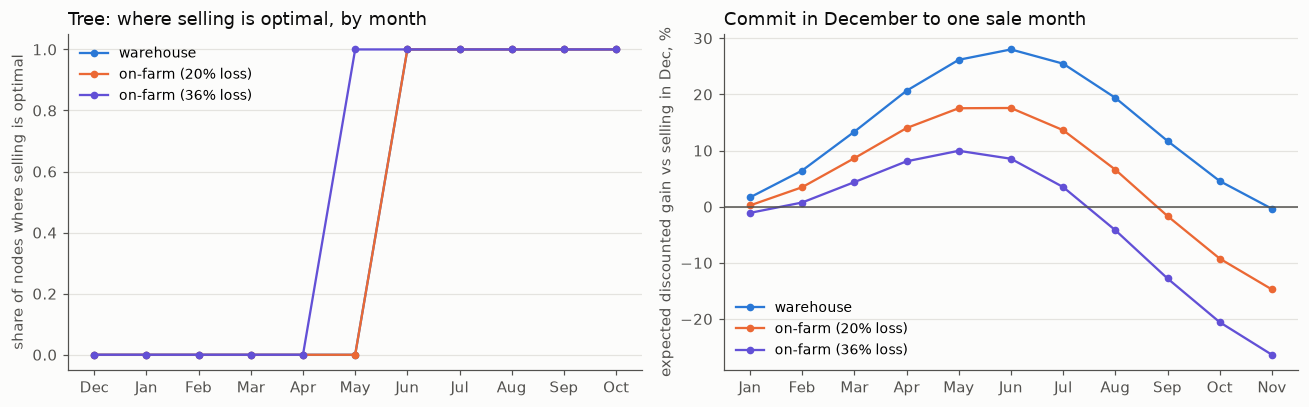

,tree value,best fixed month,fixed-month value,tree − best fixed month
scenario,,,,
warehouse,1.28010,Jun,1.28010,0.0
on-farm (20% loss),1.17579,Jun,1.17579,0.0
on-farm (36% loss),1.09956,May,1.09956,0.0


In [19]:
k = 8
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
summary = []
for (name, c), col in zip(SCENARIOS.items(), [BLUE, ORANGE, VIOLET]):
    v, ex = store_value(c["fee"], c["loss"], k=k)
    # nodes at month-end i*k (i = 1..H-1) and the decision at December itself (i = 0)
    share = [len(ex[i * k]) / (i * k + 1) for i in range(H)]
    tm = np.arange(1, H + 1) / 12
    fixed = np.exp(np.cumsum(mu[SELL_MONTHS].values / 12) - (R_LOAN + c["fee"] + c["loss"]) * tm)
    axes[0].plot(range(H), share, "o-", color=col, ms=4, label=name)
    axes[1].plot(range(1, H + 1), 100 * (fixed - 1), "o-", color=col, ms=4, label=name)
    best = int(np.argmax(fixed))
    summary.append({"scenario": name, "tree value": v, "best fixed month": SELL_MONTHS[best],
                    "fixed-month value": fixed[best], "tree − best fixed month": v - fixed[best]})
axes[0].set_xticks(range(H), ["Dec"] + SELL_MONTHS[:H - 1])
axes[0].set_ylabel("share of nodes where selling is optimal")
axes[0].set_title("Tree: where selling is optimal, by month", loc="left", color=INK)
axes[1].set_xticks(range(1, H + 1), SELL_MONTHS)
axes[1].axhline(0, color=INK2, lw=1)
axes[1].set_ylabel("expected discounted gain vs selling in Dec, %")
axes[1].set_title("Commit in December to one sale month", loc="left", color=INK)
for ax in axes:
    ax.grid(axis="x", visible=False); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()
pd.DataFrame(summary).set_index("scenario").round(5)

**Reading — and an important limitation of the GBM model.**

* Storing pays in every scenario: ≈ +27% of the December price in a warehouse (net of the
  one-off fee), ≈ +18% on-farm at 20%/yr losses, ≈ +10% on-farm at 36%/yr. Most of the
  difference between warehouse and on-farm storage is the loss rate.
* The tree value has converged already at one step per month and equals the **best fixed
  month** exactly: the optimal policy is "hold until the end of May/June, then sell", and at
  each month either *every* node sells or *none* does.

This is not a numerical accident. The payoff is the price $S$, every cost is proportional to
$S$, and under GBM the expected future growth does not depend on the current price. So the
value is $V(S,t) = S\,f(t)$ and the comparison "sell now vs wait" is the same at every price —
the decision depends only on the calendar. Under this model the option to wait is worth
exactly what the best calendar month is worth; a price-dependent rule ("sell once the price
reaches X") cannot appear.

A price-dependent rule needs the price **level** to carry information about future growth.
The checks below ask whether the data shows that (mean reversion).

In [20]:
lp_full = np.log(price).reindex(pd.period_range("2006-01", "2025-12", freq="M"))

# (1) across seasons: harvest price relative to the previous ~3 years vs the rise to May-Jul
rows = []
for yr in range(2007, 2026):
    h = lp_full[[pd.Period(f"{yr-1}-12", "M"), pd.Period(f"{yr}-01", "M")]].mean()
    lean = lp_full[[pd.Period(f"{yr}-{m:02d}", "M") for m in (5, 6, 7)]].mean()
    prev = lp_full[(lp_full.index >= pd.Period(f"{yr-4}-01", "M")) & (lp_full.index <= pd.Period(f"{yr-1}-11", "M"))].mean()
    if np.isfinite(h) and np.isfinite(lean) and np.isfinite(prev):
        rows.append({"season": yr, "harvest vs previous 3 yrs (log)": h - prev, "rise to May–Jul (log)": lean - h})
across = pd.DataFrame(rows)
lr_ = stats.linregress(across.iloc[:, 1], across.iloc[:, 2])
sp_ = stats.spearmanr(across.iloc[:, 1], across.iloc[:, 2])
print(f"(1) across {len(across)} seasons: slope {lr_.slope:.2f} (se {lr_.stderr:.2f}, p = {lr_.pvalue:.2f}); "
      f"Spearman rho {sp_.correlation:.2f} (p = {sp_.pvalue:.2f})")

# (2) within the series: de-seasonalized level relative to its trailing 2-year average vs the next h months
eps_full = eps.reindex(lp_full.index)
level = eps_full.fillna(0).cumsum()
dev = level - level.rolling(24, min_periods=18).mean().shift(1)
for h in (1, 3, 6):
    fwd = sum(eps_full.shift(-i) for i in range(1, h + 1))
    j = pd.concat([dev, fwd], axis=1).dropna()
    s_ = stats.linregress(j.iloc[:, 0], j.iloc[:, 1])
    print(f"(2) next {h} months: slope {s_.slope:.3f} (se {s_.stderr:.3f}, naive p = {s_.pvalue:.3f}, n = {len(j)})")

(1) across 17 seasons: slope -0.35 (se 0.28, p = 0.24); Spearman rho -0.22 (p = 0.40)
(2) next 1 months: slope -0.041 (se 0.028, naive p = 0.146, n = 202)
(2) next 3 months: slope -0.141 (se 0.050, naive p = 0.006, n = 194)
(2) next 6 months: slope -0.291 (se 0.069, naive p = 0.000, n = 185)


**Reading.** Both checks point the same way — a price that is high relative to its recent level
tends to rise less afterwards — but the evidence is only suggestive: across 17 seasons the
slope is not significant, and the within-series p-values are **overstated** (overlapping
windows; regressions of future returns on a deviation from a moving average are biased toward
finding reversion). If mean reversion is real, the optimal rule would sell earlier when the price
is unusually high — a genuinely price-dependent boundary — and the GBM value above is the
"calendar-only" benchmark that such a model must beat in the Step 8 backtest.

## Step 7 — Check the tree with Monte Carlo (Lecture 2)

Under GBM the optimal policy is "sell at the end of the best month" (Step 6). Simulate
200,000 price paths from December with `qk.gbm_paths` (same drift $\mu(m)$ and σ), sell each
path at that month, discount by interest, fees and losses, and compare the mean
(`qk.mc_estimate`) with the tree. This checks the drift conversion and the discounting
independently of the tree.

In [21]:
mc_rows = []
for name, c in SCENARIOS.items():
    cost = R_LOAN + c["fee"] + c["loss"]
    tm = np.arange(1, H + 1) / 12
    fixed = np.exp(np.cumsum(mu[SELL_MONTHS].values / 12) - cost * tm)
    j = int(np.argmax(fixed))                                  # index of the best sale month
    S = qk.gbm_paths(1.0, sigma, H / 12, 0.0, H * 8, 200_000,
                     mu=np.repeat(mu[SELL_MONTHS].values, 8), rng=rng)
    pay = S[:, (j + 1) * 8] * np.exp(-cost * (j + 1) / 12)
    mean, se = qk.mc_estimate(pay)
    tree = store_value(c["fee"], c["loss"])[0]
    mc_rows.append({"scenario": name, "sell in": SELL_MONTHS[j], "Monte Carlo": mean, "SE": se,
                    "tree": tree, "(MC − tree) / SE": (mean - tree) / se})
pd.DataFrame(mc_rows).set_index("scenario").round(4)

,sell in,Monte Carlo,SE,tree,(MC − tree) / SE
scenario,,,,,
warehouse,Jun,1.2806,0.0008,1.2801,0.6152
on-farm (20% loss),Jun,1.1765,0.0008,1.1758,0.8834
on-farm (36% loss),May,1.1004,0.0006,1.0996,1.2828


The Monte Carlo mean agrees with the tree to within 1.3 standard errors in every scenario.

## Step 8 — Backtest on real seasons (main validation)

Does storing actually pay on the **real** Eldoret price paths, after interest, fees and losses?
For every season with a December price (Dec 2006 → Dec 2022 starts; Dec 2023 and Dec 2024 are
missing), with **no look-ahead**:

1. re-estimate the seasonal drift and σ using only data up to the November before the season;
2. choose the sale month that the model says is best for that season's costs (Step 6);
3. compute the realized net gain per KSh of December price,
   $\;P_{\text{sale}}/P_{\text{Dec}} \cdot e^{-(r+\text{fee}+\text{loss})\,t} - 1 - \text{one-off fee}$,
   against **selling at harvest** (gain 0). If the planned month has no price, sell at the next
   observed month.

In [22]:
def model_until(t_end):
    # seasonal log drift and sigma re-estimated with returns up to t_end (Step 3 / 4 methods)
    rr = r[r.index <= t_end]
    g_ = pd.Series(g_of(fit_drift(rr, K), K), index=MONTHS)
    s_ = qk.annualized_vol(rr - g_.values[rr.index.month - 1], 12)
    return g_, 12 * g_ + 0.5 * s_ ** 2

def season_gain(y, c, X=np.inf):
    # realized gain for the season starting December y-1; X = optional early-sale threshold (below)
    d0 = pd.Period(f"{y-1}-12", "M")
    if d0 not in price.index or np.isnan(price[d0]):
        return np.nan, None
    g_, mu_ = model_until(d0 - 1)
    cost = R_LOAN + c["fee"] + c["loss"]
    tm = np.arange(1, H + 1) / 12
    fixed = np.exp(np.cumsum(mu_[SELL_MONTHS].values / 12) - cost * tm)
    if fixed.max() <= 1:
        return 0.0, "Dec"                                       # model says sell at harvest
    j = int(np.argmax(fixed)) + 1                               # planned sale: end of month j (1 = Jan)
    cg = np.cumsum(g_[SELL_MONTHS].values)                      # typical log path from December
    for i in range(1, H + 1):
        p = price.get(d0 + i, np.nan)
        if np.isnan(p):
            continue
        if i >= j or p / price[d0] >= (1 + X) * np.exp(cg[i - 1]):
            return p / price[d0] * np.exp(-cost * i / 12) - 1 - c["once"], SELL_MONTHS[i - 1]
    return np.nan, None

SC_BT = {k_: SCENARIOS[k_] for k_ in ["warehouse", "on-farm (20% loss)"]}
rows = []
for y in range(2007, 2026):
    rec = {"season (Dec start)": y - 1}
    for name, c in SC_BT.items():
        gain, month = season_gain(y, c)
        rec[f"{name}: sold in"] = month
        rec[f"{name}: gain"] = gain
    rows.append(rec)
bt = pd.DataFrame(rows).set_index("season (Dec start)")
bt.round(3)

,warehouse: sold in,warehouse: gain,on-farm (20% loss): sold in,on-farm (20% loss): gain
season (Dec start),,,,
2006,Jun,0.051,Jun,-0.021
2007,Jun,0.323,Jun,0.229
2008,Jul,0.532,Jul,0.401
2009,Jul,-0.540,Jul,-0.570
2010,Jun,1.495,May,1.215
2011,Jun,-0.008,Jun,-0.075
2012,Jun,-0.031,Jun,-0.096
2013,Jun,0.124,Jun,0.046
2014,Jun,0.350,Jun,0.254


,seasons,mean gain,median,worst,seasons storing won,95% CI low (bootstrap),95% CI high,mean excl. 2022–23 spike seasons
scenario,,,,,,,,
warehouse,17,0.284,0.171,-0.54,13/17,0.070,0.516,0.248
on-farm (20% loss),17,0.151,0.090,-0.57,12/17,-0.018,0.334,0.143


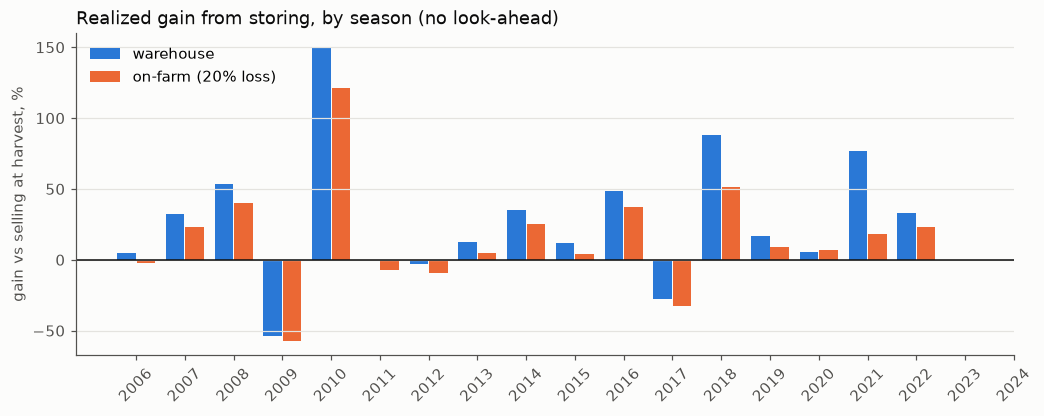

In [23]:
brng = np.random.default_rng(2026)
summ = []
for name in SC_BT:
    x = bt[f"{name}: gain"].dropna()
    reps = [brng.choice(x.values, len(x)).mean() for _ in range(5000)]
    ex = x.drop([2021, 2022], errors="ignore")                 # seasons starting Dec 2021 / Dec 2022
    summ.append({"scenario": name, "seasons": len(x), "mean gain": x.mean(), "median": x.median(),
                 "worst": x.min(), "seasons storing won": f"{int((x > 0).sum())}/{len(x)}",
                 "95% CI low (bootstrap)": np.quantile(reps, .025), "95% CI high": np.quantile(reps, .975),
                 "mean excl. 2022–23 spike seasons": ex.mean()})
display(pd.DataFrame(summ).set_index("scenario").round(3))

fig, ax = plt.subplots(figsize=(11, 3.8))
xs = np.arange(len(bt))
for (name, col), off in zip([("warehouse", BLUE), ("on-farm (20% loss)", ORANGE)], [-0.2, 0.2]):
    ax.bar(xs + off, 100 * bt[f"{name}: gain"].values, width=0.38, color=col, label=name)
ax.axhline(0, color=INK, lw=1)
ax.set_xticks(xs, bt.index, rotation=45)
ax.set_ylabel("gain vs selling at harvest, %")
ax.set_title("Realized gain from storing, by season (no look-ahead)", loc="left", color=INK)
ax.legend(frameon=False); ax.grid(axis="x", visible=False)
plt.show()

**A price-dependent rule, tested on data.** GBM says the decision depends only on the calendar.
Does the data disagree? Test a simple rule: sell *before* the planned month as soon as the
price is at least $(1+X)$ times the typical seasonal path from December. $X$ is chosen each
season from {10%, 20%, 30%, 50%, never} by what would have worked best in **earlier seasons
only** (from 2012, so at least 5 earlier seasons), then applied to the next season.

In [24]:
GRID = [0.1, 0.2, 0.3, 0.5, np.inf]
thr_rows = []
for name, c in SC_BT.items():
    for y in range(2012, 2026):
        if np.isnan(season_gain(y, c)[0]):
            continue
        past = {X: np.nanmean([season_gain(yy, c, X)[0] for yy in range(2007, y)]) for X in GRID}
        Xb = max(past, key=past.get)
        thr_rows.append({"scenario": name, "season (Dec start)": y - 1, "chosen X": Xb,
                         "threshold rule": season_gain(y, c, Xb)[0], "hold to planned month": season_gain(y, c)[0]})
thr = pd.DataFrame(thr_rows)
display(thr.groupby("scenario")[["threshold rule", "hold to planned month"]].mean().round(3))
print("threshold chosen (X):", thr["chosen X"].value_counts().to_dict())

,threshold rule,hold to planned month
scenario,,
on-farm (20% loss),0.109,0.109
warehouse,0.247,0.247


threshold chosen (X): {inf: 24}


**Reading.** Storing beat selling at harvest in most seasons and the warehouse mean gain is
positive with a bootstrap interval that excludes zero; on-farm storage gains less and its
interval includes zero — losses eat most of the seasonal rise. The 2022–23 spike seasons
raise the average but do not create it (see the "excl." column). The bad seasons (starting
Dec 2009 and Dec 2017) are real losses of 28–57%: storage is profitable on average, not every
year.

The price-threshold rule never selected an early sale: in every season, "never sell early"
had worked best in the earlier seasons. Selling early because the price has run ahead of
its usual path did not pay historically — consistent with the GBM model, whose optimal rule
depends only on the calendar.

## Step 9 — Sensitivities and break-even costs (Lecture 6)

Bump-and-reprice: the model value (Step 6) and the historical mean gain (Step 8) as the loan
rate and the loss rate change. Under GBM, σ does not create option value (the policy is a
calendar rule); it enters only through the Itô term $\sigma^2/2$, so it is not varied here.

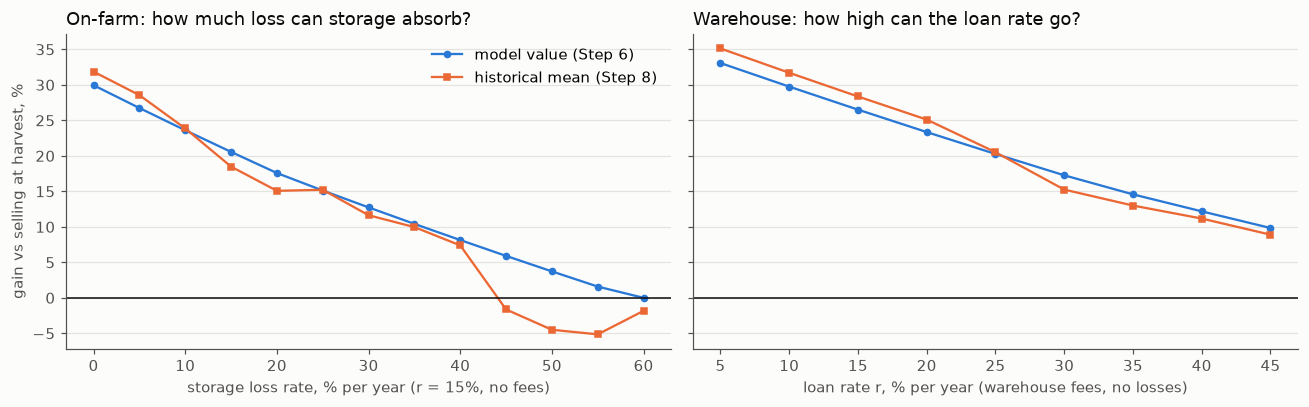

break-even on-farm loss rate (model)        60.0
break-even on-farm loss rate (history)      45.0
break-even warehouse loan rate (model)      68.0
break-even warehouse loan rate (history)    53.0
Name: % per year, dtype: float64

In [25]:
def model_gain(fee, loss, r_, once):
    return store_value(fee, loss, r_=r_)[0] - 1 - once

def hist_gain(fee, loss, r_, once):
    global R_LOAN
    old, R_LOAN = R_LOAN, r_
    try:
        return np.nanmean([season_gain(y, dict(fee=fee, loss=loss, once=once))[0] for y in range(2007, 2026)])
    finally:
        R_LOAN = old

losses = np.linspace(0, 0.6, 13)
rates = np.linspace(0.05, 0.45, 9)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
for ax, xs_, f_model, f_hist, xl in [
        (axes[0], losses, lambda x: model_gain(0, x, .15, 0), lambda x: hist_gain(0, x, .15, 0),
         "storage loss rate, % per year (r = 15%, no fees)"),
        (axes[1], rates, lambda x: model_gain(.03, 0, x, .015), lambda x: hist_gain(.03, 0, x, .015),
         "loan rate r, % per year (warehouse fees, no losses)")]:
    ax.plot(100 * xs_, [100 * f_model(x) for x in xs_], "o-", color=BLUE, ms=4, label="model value (Step 6)")
    ax.plot(100 * xs_, [100 * f_hist(x) for x in xs_], "s-", color=ORANGE, ms=4, label="historical mean (Step 8)")
    ax.axhline(0, color=INK, lw=1); ax.set_xlabel(xl); ax.grid(axis="x", visible=False)
axes[0].set_ylabel("gain vs selling at harvest, %"); axes[0].legend(frameon=False)
axes[0].set_title("On-farm: how much loss can storage absorb?", loc="left", color=INK)
axes[1].set_title("Warehouse: how high can the loan rate go?", loc="left", color=INK)
plt.tight_layout(); plt.show()

def first_zero(f, grid):
    # smallest cost on the grid at which the gain is no longer positive (storage stops paying)
    for x in grid:
        if f(x) <= 1e-6:
            return x
    return np.nan

fine_loss, fine_rate = np.arange(0, 1.001, 0.01), np.arange(0, 1.001, 0.01)
be = {
    "break-even on-farm loss rate (model)": first_zero(lambda x: model_gain(0, x, .15, 0), fine_loss),
    "break-even on-farm loss rate (history)": first_zero(lambda x: hist_gain(0, x, .15, 0), fine_loss),
    "break-even warehouse loan rate (model)": first_zero(lambda x: model_gain(.03, 0, x, .015), fine_rate),
    "break-even warehouse loan rate (history)": first_zero(lambda x: hist_gain(.03, 0, x, .015), fine_rate),
}
pd.Series(be).mul(100).round(1).rename("% per year")

**Reading.** The break-even numbers are the most useful output for agriBORA: storage keeps
paying until the loss rate or the loan rate reaches the printed levels. A certified warehouse
removes losses, so its margin is set by the loan rate (break-even ≈ 53–68%/yr, far above
Kenyan lending rates of ≈ 15%). On-farm storage is limited by losses: break-even ≈ 45–60%/yr,
so typical Kenyan on-farm losses of 20–36%/yr still leave a positive but much thinner margin.
The historical break-evens are lower than the model's because real seasons include the
large losing years.

## Conclusions

* **Seasonality is real and stable** (Step 2): Eldoret prices rise from the December–January
  harvest to a May–July peak in 15 of 17 seasons; the expected rise to June is ≈ 34%.
* **The seasonal model forecasts** (Step 5): at 3 months it beats the random walk out of sample.
* **Value of storage** (Step 6): ≈ +27% of the December price in a certified warehouse at a 15%
  loan rate, ≈ +18% on-farm at 20%/yr losses; best sale month June (May at high losses).
* **Under GBM the "option" is a calendar decision**: with a price payoff and proportional costs
  the tree value equals the best fixed month exactly — waiting has no option value beyond
  timing. A price-threshold rule tested out of sample (Step 8) never improved on it.
* **On real seasons** (Step 8): warehouse storage gained ≈ +28% on average (95% CI 7–52%) and
  won 13 of 17 seasons, but lost 28–57% in the two worst seasons; on-farm storage gained about
  half as much and its average is not clearly above zero (CI −2% to 33%).
* **Break-evens** (Step 9): storage stops paying at a loan rate of ≈ 53% (history) to 68%
  (model) in a warehouse, or a loss rate of ≈ 45–60%/yr on-farm.

**Limitations.** One wholesale market (Eldoret), not farm-gate or agriBORA prices; monthly data
with 9 missing months; 17 seasons; costs from 2020–26 sources applied to 2006–25; a
risk-neutral farmer (no penalty for the bad years); GBM's fat-tail, volatility-clustering and
year-to-year mean-reversion departures (Step 4) are not modelled — the backtest on real paths is
the check against them; no policy shocks (import waivers, NCPB purchases).